# Práctica de Radiación: Calibración de Piranómetros
***

*Ismael Darias Darias* &emsp;&emsp; *Máster en Geofísica y Meteorología*

*Instrumentación en geofísica y meteorología (meteorología)* &emsp;&emsp; *Universidad de Granada*

En esta práctica se aportan datos de tres piranómetros CM-11 distintos, colocados en los días 23, 24 y 25 de octubre de 2017. Estos han sido instalados en la terraza de IISTA/CEAMA, en Granada, para poder ser calibrados con un cuarto piranómetro de referencia. Este piranómetro tiene una constante de calibración de $4.94\cdot 10^{-3}$ mV/W$m^{-2}$. La resolución de las medidas es de un minuto, siendo cada medida el promedio de las medidas tomadas cada 5 segundos.

La idea es realizar la calibración de los instrumentos siguiendo los siguientes pasos:
1. Visualización y preparación de los datos.
2. Eliminar los datos incorrectos.
3. Aplicar la calibración para obtener irradiancia.
4. Ajustar los datos de referencia con los piranómetros a calibrar.
5. Representar el error relativo de la irradiancia de cada piranómetro.

In [1]:
# Importación previa
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuración de tamaños de fuente
plt.rc('figure', titlesize=20)
plt.rc('axes', titlesize=20, labelsize=18)
plt.rc('xtick', labelsize=16)
plt.rc('ytick', labelsize=16)
plt.rc('legend', fontsize=16)

### Visualización y preparación de los datos

Empezamos abriendo el fichero de datos con pandas. Una vez hecho esto, renombramos las columnas de forma intuitiva para poder manejar los datos correctamente. Además, como se han observado datos con valores -6999 en la vista previa, podemos clasificar estos directamente como NaN y eliminarlos.

In [2]:
# Definimos las columnas
cols = ['indicador', 'year', 'dia', 'hora', 'status', 'bateria', 'CM11_ref', 'CM11_43', 'CM11_44', 'CM11_46']

# Abrimos el archivo. Opcionalmente, podemos tratar los valores -6999 como NaN
df = pd.read_csv('datos_calibracionOct17_EPSC.dat.txt', sep = r'\s+', names = cols, na_values =[-6999])

# Eliminamos los valores nulos
df = df.dropna().copy()

In [3]:
# Visualizamos
df.head(8)

,indicador,year,dia,hora,status,bateria,CM11_ref,CM11_43,CM11_44,CM11_46
11,101,2017,296,1011,0,12.69,1.564,2.735,2.431,1.401
14,101,2017,296,1014,0,11.59,1.423,2.745,2.343,1.201
15,101,2017,296,1016,0,12.25,1.418,2.846,2.178,1.095
16,101,2017,296,1017,0,12.24,1.361,2.693,2.455,1.028
17,101,2017,296,1018,0,13.94,1.687,2.734,2.589,1.493
18,101,2017,296,1019,0,12.67,1.573,2.770,2.401,1.516
19,101,2017,296,1020,0,12.89,1.493,2.792,2.387,1.301
20,101,2017,296,1020,0,12.25,1.074,2.746,1.998,0.827


Se observa que el día no se escribe en formato fecha, sino como día juliano. Además, la hora viene dada en formato Campbell. De forma previa, se puede corregir esta columna para que dé la hora correctamente.

In [4]:
# Lo hacemos función para poder aplicar la función pd.apply
def conversion_tiempo(df):
    hora_str = f"{int(df['hora']):04d}"

    h, m = int(hora_str[:2]), int(hora_str[2:])

    # Teniendo en cuenta que 2400 es el día siguiente
    if h == 24:
        return pd.to_datetime(f"{int(df['year'])}{int(df['dia'])}", format = '%Y%j') + pd.Timedelta(days = 1)
    return pd.to_datetime(f"{int(df['year'])} {int(df['dia'])} {h:02d}:{m:02}", format = '%Y %j %H:%M')

# Aplicamos
df['fecha'] = df.apply(conversion_tiempo, axis = 1)

# Hacemos índice
df.set_index('fecha', inplace = True)

C:\Users\ismae\AppData\Local\Temp\ipykernel_3172\3647190340.py:16: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.set_index('fecha', inplace = True)


In [5]:
df.head(8)

,indicador,year,dia,hora,status,bateria,CM11_ref,CM11_43,CM11_44,CM11_46
fecha,,,,,,,,,,
2017-10-23 10:11:00,101,2017,296,1011,0,12.69,1.564,2.735,2.431,1.401
2017-10-23 10:14:00,101,2017,296,1014,0,11.59,1.423,2.745,2.343,1.201
2017-10-23 10:16:00,101,2017,296,1016,0,12.25,1.418,2.846,2.178,1.095
2017-10-23 10:17:00,101,2017,296,1017,0,12.24,1.361,2.693,2.455,1.028
2017-10-23 10:18:00,101,2017,296,1018,0,13.94,1.687,2.734,2.589,1.493
2017-10-23 10:19:00,101,2017,296,1019,0,12.67,1.573,2.770,2.401,1.516
2017-10-23 10:20:00,101,2017,296,1020,0,12.89,1.493,2.792,2.387,1.301
2017-10-23 10:20:00,101,2017,296,1020,0,12.25,1.074,2.746,1.998,0.827


### Eliminación de datos incorrectos

Para este primer paso, debemos tener en cuenta varios factores:
- En primer lugar, los datos nocturnos no son válidos. Para eliminarlos de la serie temporal del calibrado, los representamos y buscamos un criterio que elimine de forma bruta.
- Los datos nubosos seguirán un procedimiento similar, de forma que se trunquen aquellos datos de formas anómalas.
- Por último, la batería debe ser estable, por lo que se ha de aplicar un criterio. Para ello, suponemos que la batería fluctúa entre 1 y 2 voltios de su valor de 12 voltios. Por lo que los datos cuya batería esté por encima de esto, los eliminamos.

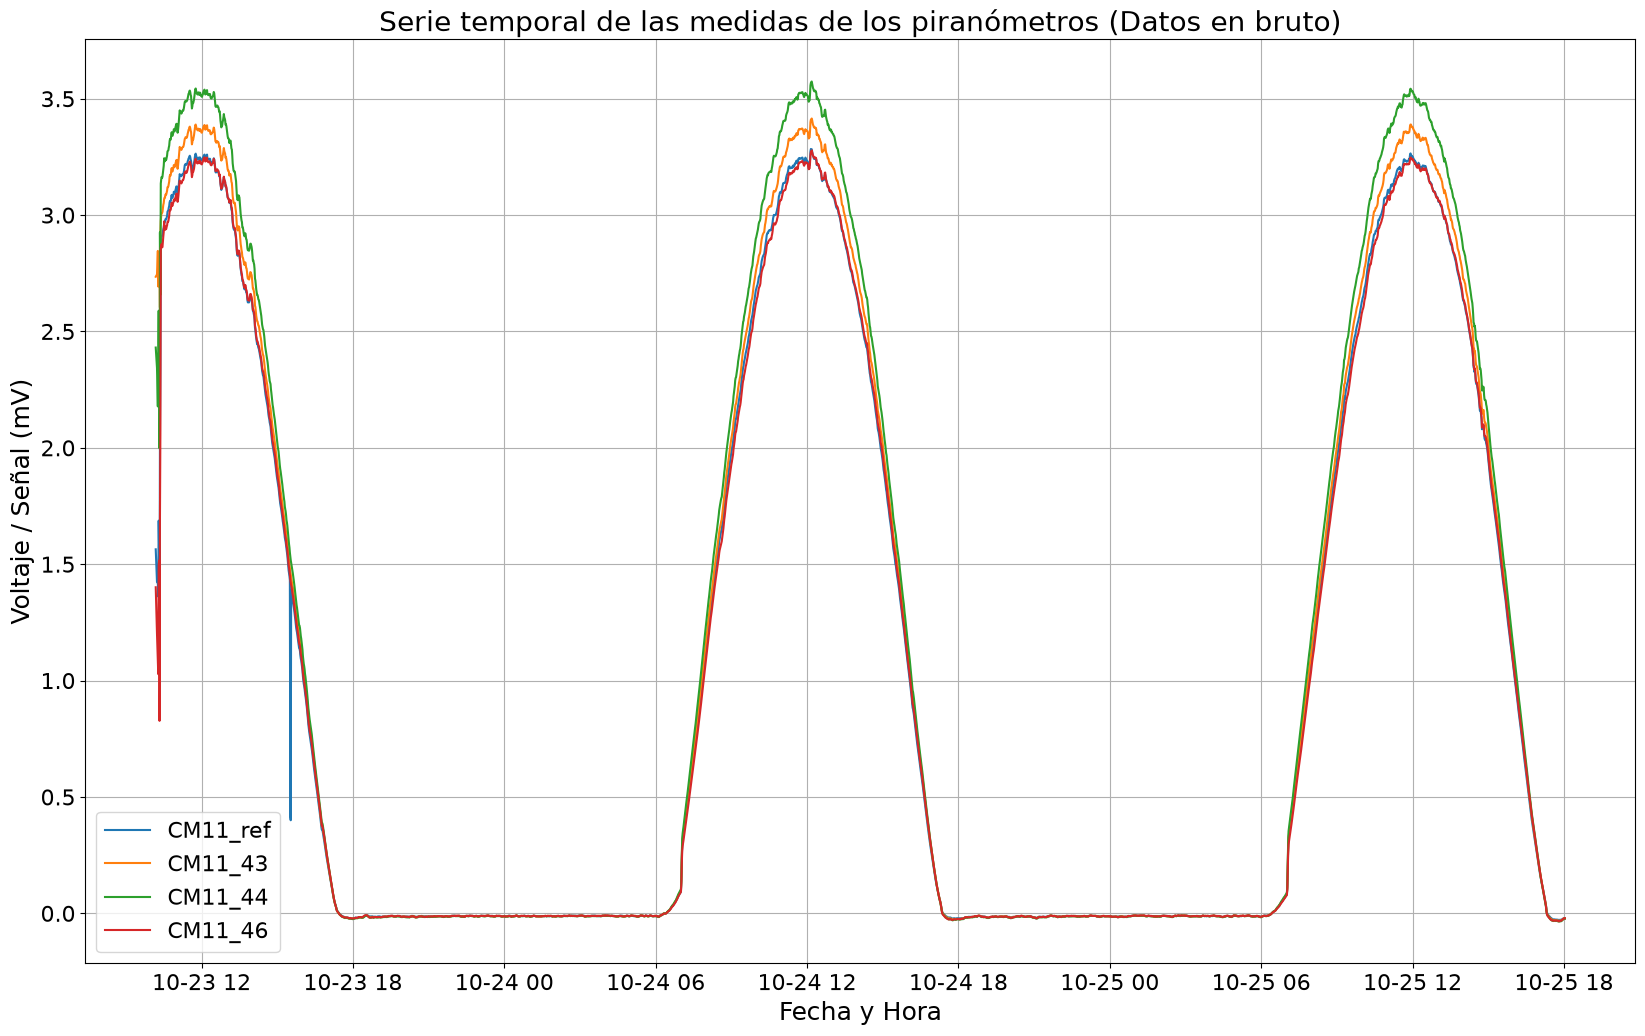

In [6]:
# Representamos la serie temporal de cada piranómetro
fig, ax = plt.subplots(figsize = (20,12))

ax.plot(df.index, df['CM11_ref'], label='CM11_ref')
ax.plot(df.index, df['CM11_43'], label='CM11_43')
ax.plot(df.index, df['CM11_44'], label='CM11_44')
ax.plot(df.index, df['CM11_46'], label='CM11_46')

ax.set_title('Serie temporal de las medidas de los piranómetros (Datos en bruto)', fontsize=20)
ax.set_ylabel('Voltaje / Señal (mV)', fontsize=18)
ax.set_xlabel('Fecha y Hora', fontsize=18)
ax.tick_params(axis='both', which='major', labelsize=16)

plt.grid()

ax.legend(fontsize=16)
plt.savefig('./Informe/Images/Datos_brutos')
plt.savefig('./Images/Datos_brutos')
plt.show()

Viendo la serie temporal, podemos ver que los datos están prácticamente en condiciones óptimas. Se observa un dato anómalo en el instrumento de referencia, posiblemente debido a efectos de sombra o nubosidad. Para descartar que se deba a efectos de batería, aplicaremos primero los filtrados por batería y nocturnidad para volver a ver la forma de la serie temporal.

Por inspección visual, en primera aproximación, se ha decidido que se consideran datos nubosos o nocturnos aquellos con un valor de voltaje negativo. Sin embargo, tras medir los errores relativos, parece más acertado usar 0.2 mV como umbral.

In [7]:
# Limpieza de datos con bateria en mal estado
umbral_bat = 2 # Voltios
df = df[(df['bateria'] >= (12 - umbral_bat)) & (df['bateria'] <= (12 + umbral_bat)) ].copy()

# Eliminamos datos negativos
umbral_di = 0.2
df = df[(df['CM11_ref'] > umbral_di) & (df['CM11_43'] > umbral_di) & (df['CM11_44'] > umbral_di) & (df['CM11_46'] > umbral_di)].copy()

Además, también se ha visto que los primeros datos del día 23 son erróneos, por lo que han de ser eliminados.

In [8]:
# Eliminación de primeros días
indices_descarte = df.loc['2017-10-23 10:11':'2017-10-23 10:24'].index.union( df.loc['2017-10-23 15:31':'2017-10-23 15:32'].index)
df = df.drop(indices_descarte).copy()

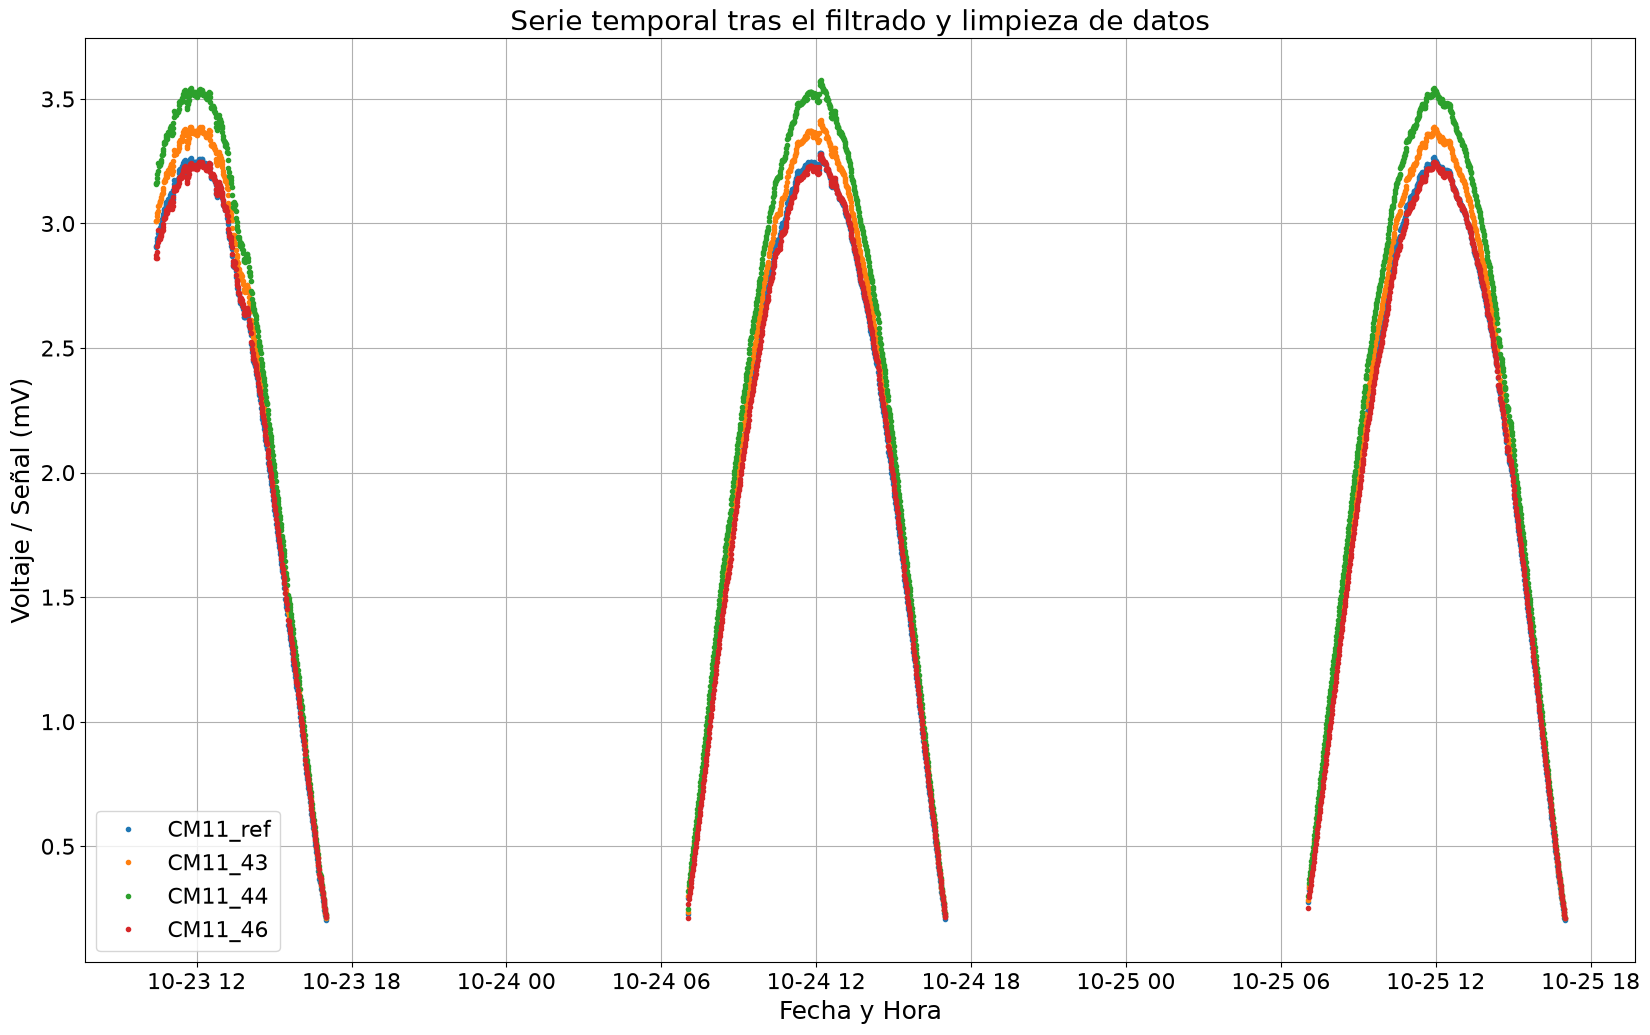

In [9]:
# Representamos tras el filtrado
fig, ax = plt.subplots(figsize = (20,12))

ax.plot(df.index, df['CM11_ref'], '.', label='CM11_ref')
ax.plot(df.index, df['CM11_43'], '.', label='CM11_43')
ax.plot(df.index, df['CM11_44'], '.', label='CM11_44')
ax.plot(df.index, df['CM11_46'], '.', label='CM11_46')

ax.set_title('Serie temporal tras el filtrado y limpieza de datos', fontsize=20)
ax.set_ylabel('Voltaje / Señal (mV)', fontsize=18)
ax.set_xlabel('Fecha y Hora', fontsize=18)
ax.tick_params(axis='both', which='major', labelsize=16)

plt.grid()

ax.legend(fontsize=16)
plt.savefig('./Informe/Images/Datos_limpios')
plt.savefig('./Images/Datos_limpios')
plt.show()

Esta serie se encuentra ya corregida y lista para el calibrado.

### Calibración

Para hacer la calibración, el procedimiento es similar al de las prácticas anteriores. Obtenemos la serie de irradiancias solares del piranómetro de referencia. Suponiendo estos como los datos reales, ajustamos los valores del voltaje de cada piranómetro frente a las irradiancias del piranómetro de referencia. La idea es ajustarlos a una recta del tipo: $$I = a\cdot V + b$$
donde $a$ corresponde a la constante de calibración, $V$ a los valores de voltaje y $b$ al offset del instrumento.

In [10]:
# Definimos constante de calibración de referencia
aref = 1 / (4.94 * (10 ** (-3))) # Wm-2/mV

# Calculamos los valores de irradiancia
df['I_ref'] = df['CM11_ref'] * aref

# Usamos polyfit para hacer los distintos ajustes
a_43, b_43 = np.polyfit(df['CM11_43'], df['I_ref'], 1) 
a_44, b_44 = np.polyfit(df['CM11_44'], df['I_ref'], 1)
a_46, b_46 = np.polyfit(df['CM11_46'], df['I_ref'], 1)

# Creamos una función génerica que dado los coeficientes y valores devuelva las irradiancias
def irradian(a, b, V):
    return (a * V + b)

# Calculamos para cada piranómetro
df['I_43'] = irradian(a_43, b_43, df['CM11_43'])
df['I_44'] = irradian(a_44, b_44, df['CM11_44'])
df['I_46'] = irradian(a_46, b_46, df['CM11_46'])

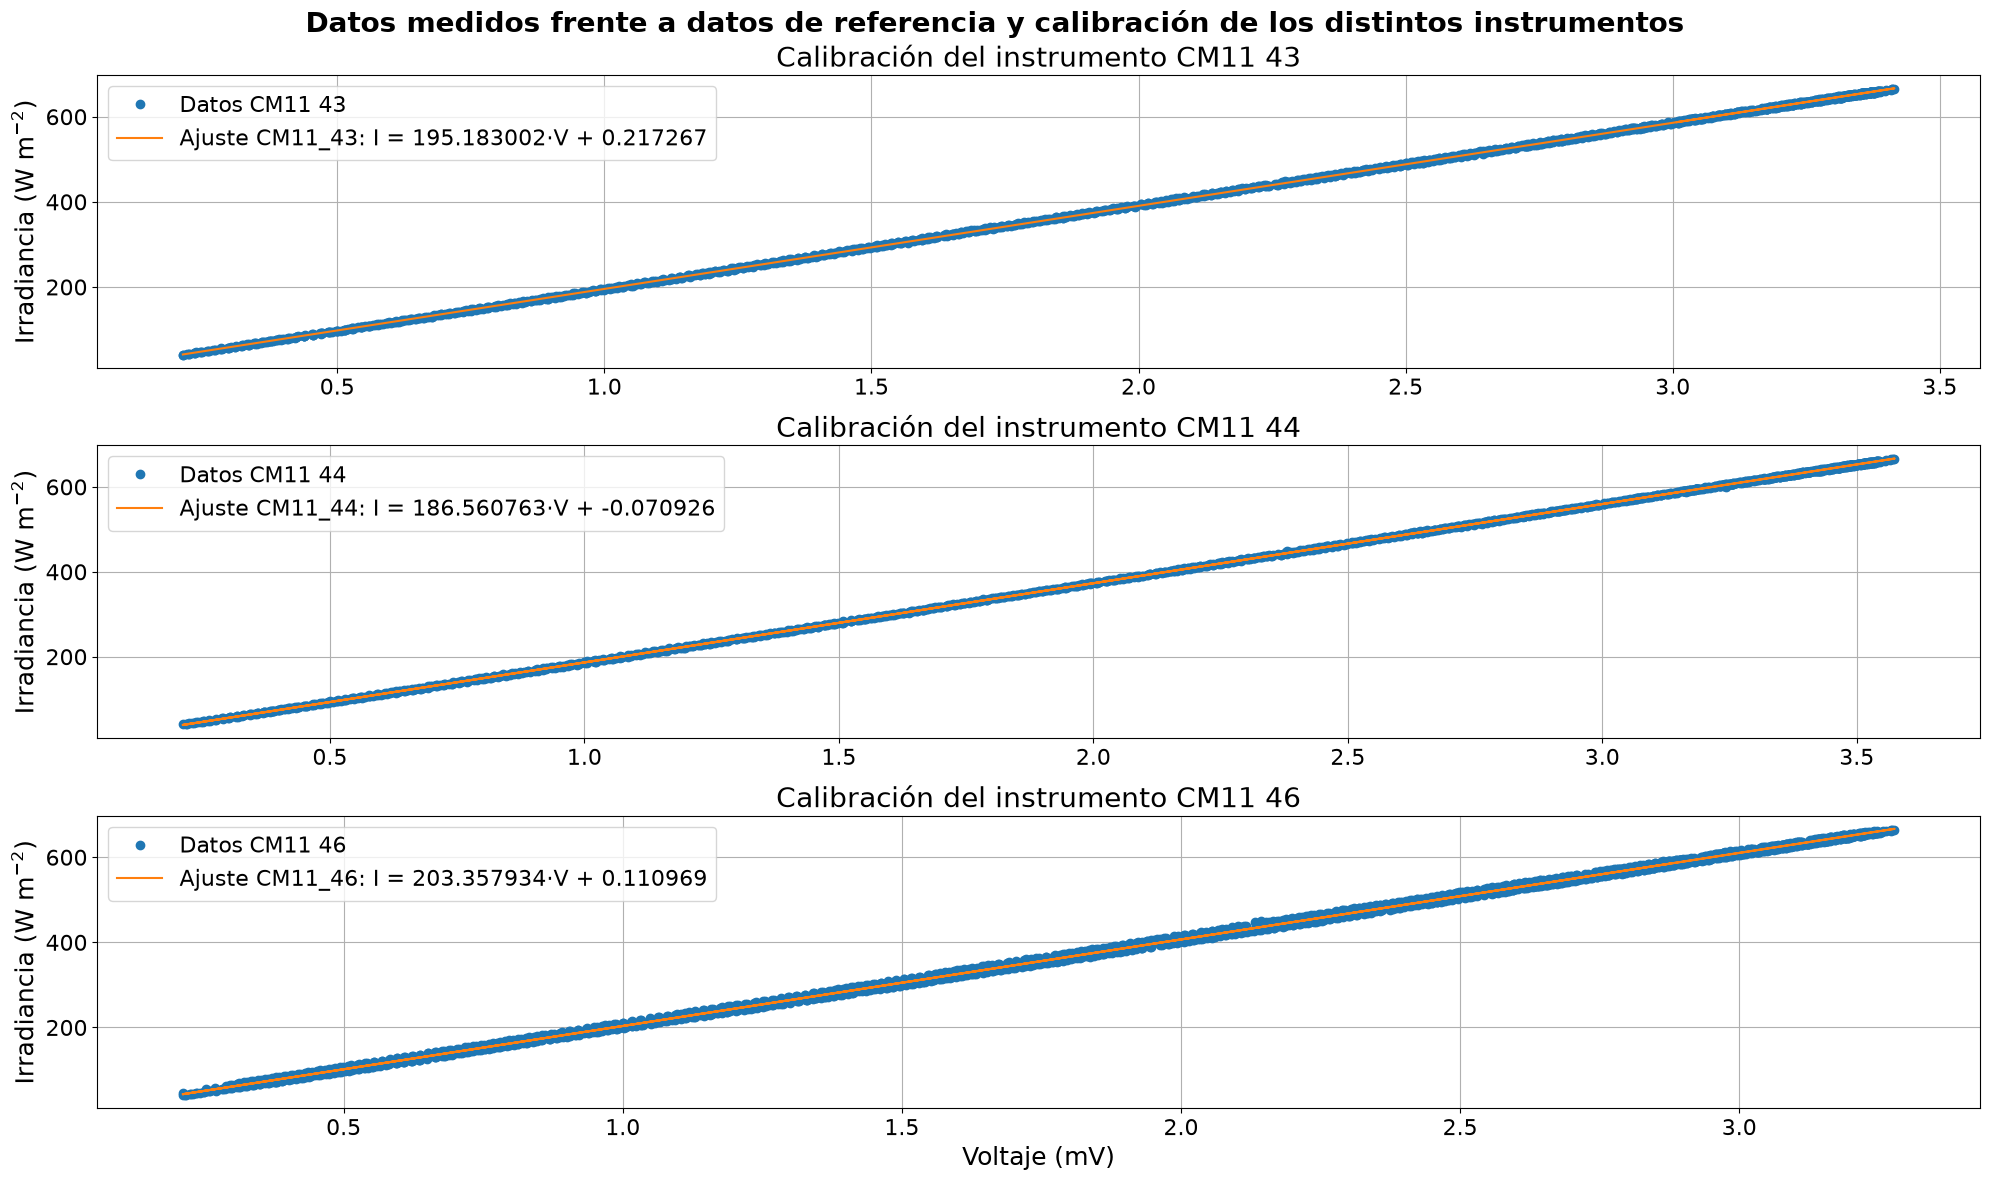

In [11]:
# Representamos Ajustes
fig, (ax1, ax2, ax3) = plt.subplots(ncols = 1, nrows = 3, figsize = (20, 12))

# CM11 43
ax1.plot(df['CM11_43'], df['I_ref'], 'o', label = 'Datos CM11 43')
ax1.plot(df['CM11_43'], df['I_43'], label = rf'Ajuste CM11_43: I = {a_43:2f}$\cdot$V + {b_43:2f}')

ax1.set_title('Calibración del instrumento CM11 43', fontsize = 20)
ax1.set_ylabel(r'Irradiancia (W m$^{-2}$)', fontsize = 18)
ax1.tick_params(axis='both', which='major', labelsize = 16)
ax1.legend(fontsize = 16)
ax1.grid()

# CM11 44
ax2.plot(df['CM11_44'], df['I_ref'], 'o', label = 'Datos CM11 44')
ax2.plot(df['CM11_44'], df['I_44'], label = rf'Ajuste CM11_44: I = {a_44:2f}$\cdot$V + {b_44:2f}')

ax2.set_title('Calibración del instrumento CM11 44', fontsize = 20)
ax2.set_ylabel(r'Irradiancia (W m$^{-2}$)', fontsize = 18)
ax2.tick_params(axis='both', which='major', labelsize = 16)
ax2.legend(fontsize = 16)
ax2.grid()

# CM11 46
ax3.plot(df['CM11_46'], df['I_ref'], 'o', label = 'Datos CM11 46')
ax3.plot(df['CM11_46'], df['I_46'], label = rf'Ajuste CM11_46: I = {a_46:2f}$\cdot$V + {b_46:2f}')

ax3.set_title('Calibración del instrumento CM11 46', fontsize = 20)
ax3.set_xlabel('Voltaje (mV)', fontsize = 18)
ax3.set_ylabel(r'Irradiancia (W m$^{-2}$)', fontsize = 18)
ax3.tick_params(axis='both', which='major', labelsize = 16)
ax3.legend(fontsize = 16)
ax3.grid()

fig.suptitle('Datos medidos frente a datos de referencia y calibración de los distintos instrumentos', fontsize = 20, fontweight = 'bold')
plt.tight_layout()
plt.savefig('./Images/Calibracion')
plt.savefig('./Informe/Images/Calibracion')

plt.show()

### Errores relativos

In [12]:
# Errores relativos
df['Error_rel_43'] = 100 * (abs(df['I_ref'] - df['I_43']) / df['I_ref'])
df['Error_rel_44'] = 100 * (abs(df['I_ref'] - df['I_44']) / df['I_ref'])
df['Error_rel_46'] = 100 * (abs(df['I_ref'] - df['I_46']) / df['I_ref'])

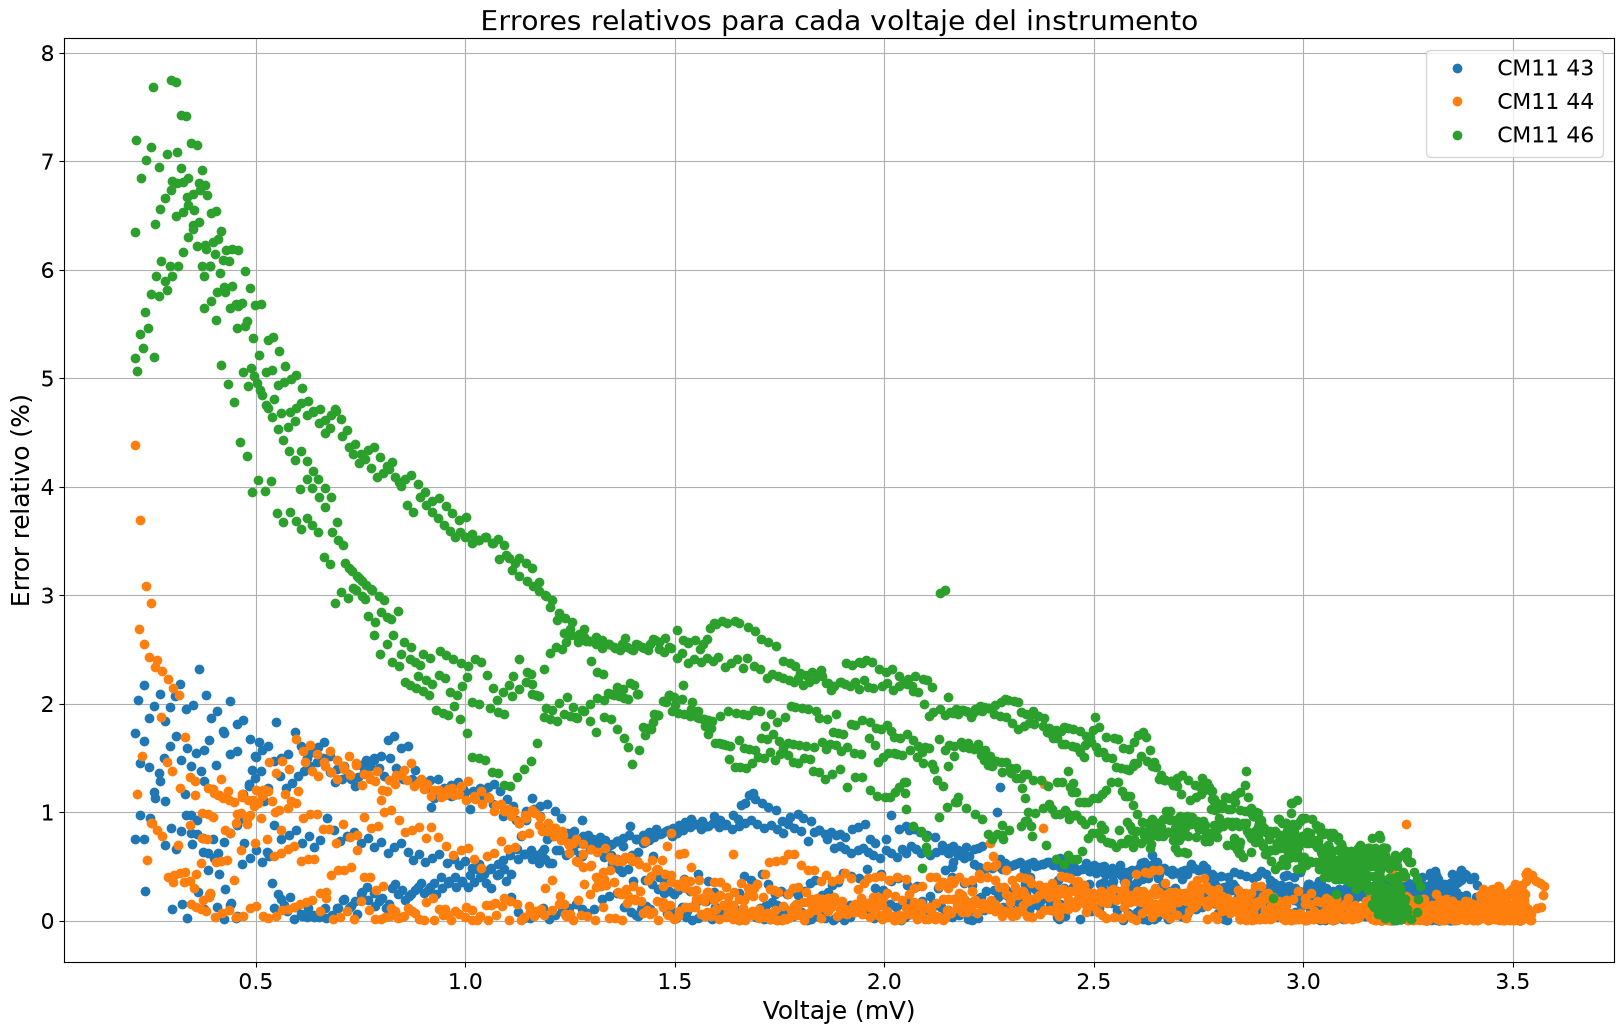

Errores relativos medios de cada instrumento y su desviación 
CM11 43: 0.407155 $\pm$ 0.409907
CM11 44: 0.288124 $\pm$ 0.407483
CM11 46: 1.75768 $\pm$ 1.60483


In [13]:
# Representamos la distribución de cada uno y damos valores de media y desviación
fig, ax = plt.subplots(figsize = (20, 12))

ax.plot(df['CM11_43'], df['Error_rel_43'], 'o', label = 'CM11 43')
ax.plot(df['CM11_44'], df['Error_rel_44'], 'o', label = 'CM11 44')
ax.plot(df['CM11_46'], df['Error_rel_46'], 'o', label = 'CM11 46')

ax.set_title('Errores relativos para cada voltaje del instrumento', fontsize = 20)
ax.set_xlabel('Voltaje (mV)', fontsize = 18)
ax.set_ylabel('Error relativo (%)', fontsize = 18)
ax.tick_params(axis='both', which='major', labelsize = 16)
ax.legend(fontsize = 16)
ax.grid()

plt.savefig('./Images/error_relativo')
plt.savefig('./Informe/Images/error_relativo')

plt.show()

# Media y desviación
print('Errores relativos medios de cada instrumento y su desviación ')
print(fr"CM11 43: {np.mean(df['Error_rel_43']):2g} $\pm$ {np.std(df['Error_rel_43']):2g}")
print(fr"CM11 44: {np.mean(df['Error_rel_44']):2g} $\pm$ {np.std(df['Error_rel_44']):2g}")
print(fr"CM11 46: {np.mean(df['Error_rel_46']):2g} $\pm$ {np.std(df['Error_rel_46']):2g}")